In [ ]:
# Installation automatique des dépendances pour Google Colab
import sys
import subprocess

def install_dependencies():
    """Installe les packages nécessaires pour Google Colab"""
    packages = ['pycryptodome', 'pillow']
    for package in packages:
        try:
            __import__(package.replace('pycryptodome', 'Crypto').replace('pillow', 'PIL'))
        except ImportError:
            print(f"[+] Installation de {package}...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
            print(f"[✓] {package} installé avec succès")

# Installation des dépendances
install_dependencies()

# Imports
from Crypto.Cipher import AES
from Crypto.Random import get_random_bytes
from Crypto.Util.Padding import pad, unpad
from PIL import Image
from IPython.display import display, Image as IPImage
import numpy as np
import math
import zlib
import os
from collections import Counter
import matplotlib.pyplot as plt

print("\n✅ Tous les modules sont chargés avec succès !")
print("📌 Passe au BLOC 2 pour uploader tes images")



✅ Tous les modules sont chargés avec succès !
📌 Passe au BLOC 2 pour uploader tes images


In [ ]:
from google.colab import files

print("📤 Upload tes images Paris8.jpg et Paris8.tiff :")
uploaded = files.upload()

# Vérification des fichiers uploadés
print("\n✅ Fichiers uploadés :")
for filename in uploaded.keys():
    print(f"   - {filename} ({len(uploaded[filename])} octets)")

print("\n📌 Passe au BLOC 3 pour définir la classe de chiffrement")



📤 Upload tes images Paris8.jpg et Paris8.tiff :


Saving Paris8.jpg to Paris8 (1).jpg
Saving Paris8.tiff to Paris8 (1).tiff

✅ Fichiers uploadés :
   - Paris8 (1).jpg (89447 octets)
   - Paris8 (1).tiff (2117800 octets)

📌 Passe au BLOC 3 pour définir la classe de chiffrement


In [ ]:
class ImageEncryptionAnalyzer:
    """
    Classe pour analyser le chiffrement d'images avec différents modes AES.
    Implémente les principes de confusion et diffusion de Shannon.
    """

    def __init__(self, key_size=128):
        """
        Initialise l'analyseur avec une clé AES aléatoire.
        Le principe de Kerckhoffs : la sécurité repose uniquement sur le secret de la clé.
        """
        self.key = get_random_bytes(key_size // 8)  # Clé de 128 bits (16 octets)
        self.block_size = AES.block_size  # 16 octets (128 bits)
        print(f"[+] Clé AES générée : {self.key.hex()[:32]}...")
        print(f"[+] Taille de clé : {key_size} bits")

    def load_image(self, image_path):
        """Charge une image et la convertit en bytes"""
        img = Image.open(image_path)
        self.original_image = img
        self.image_mode = img.mode
        self.image_size = img.size

        # Conversion en bytes
        img_array = np.array(img)
        img_bytes = img_array.tobytes()

        print(f"\n[+] Image chargée : {image_path}")
        print(f"    - Dimensions : {self.image_size}")
        print(f"    - Mode : {self.image_mode}")
        print(f"    - Taille : {len(img_bytes)} octets")

        return img_bytes, img_array.shape

    def encrypt_ecb(self, data):
        """Mode ECB (Electronic Codebook) : Cn = FK(Mn)"""
        cipher = AES.new(self.key, AES.MODE_ECB)
        padded_data = pad(data, self.block_size)
        encrypted = cipher.encrypt(padded_data)
        return encrypted, None

    def encrypt_cbc(self, data):
        """Mode CBC (Cipher Block Chaining) : Cn = FK(Mn ⊕ Cn-1)"""
        iv = get_random_bytes(self.block_size)
        cipher = AES.new(self.key, AES.MODE_CBC, iv)
        padded_data = pad(data, self.block_size)
        encrypted = cipher.encrypt(padded_data)
        return encrypted, iv

    def encrypt_cfb(self, data):
        """Mode CFB (Cipher Feedback)"""
        iv = get_random_bytes(self.block_size)
        cipher = AES.new(self.key, AES.MODE_CFB, iv, segment_size=128)
        encrypted = cipher.encrypt(data)
        return encrypted, iv

    def encrypt_ofb(self, data):
        """Mode OFB (Output Feedback)"""
        iv = get_random_bytes(self.block_size)
        cipher = AES.new(self.key, AES.MODE_OFB, iv)
        encrypted = cipher.encrypt(data)
        return encrypted, iv

    def encrypt_ctr(self, data):
        """Mode CTR (Counter)"""
        cipher = AES.new(self.key, AES.MODE_CTR)
        encrypted = cipher.encrypt(data)
        return encrypted, cipher.nonce

    def decrypt_ecb(self, encrypted_data, param, original_length):
        """Déchiffrement ECB"""
        cipher = AES.new(self.key, AES.MODE_ECB)
        decrypted = cipher.decrypt(encrypted_data)
        return unpad(decrypted, self.block_size)[:original_length]

    def decrypt_cbc(self, encrypted_data, iv, original_length):
        """Déchiffrement CBC"""
        cipher = AES.new(self.key, AES.MODE_CBC, iv)
        decrypted = cipher.decrypt(encrypted_data)
        return unpad(decrypted, self.block_size)[:original_length]

    def decrypt_cfb(self, encrypted_data, iv, original_length):
        """Déchiffrement CFB"""
        cipher = AES.new(self.key, AES.MODE_CFB, iv, segment_size=128)
        return cipher.decrypt(encrypted_data)[:original_length]

    def decrypt_ofb(self, encrypted_data, iv, original_length):
        """Déchiffrement OFB"""
        cipher = AES.new(self.key, AES.MODE_OFB, iv)
        return cipher.decrypt(encrypted_data)[:original_length]

    def decrypt_ctr(self, encrypted_data, nonce, original_length):
        """Déchiffrement CTR"""
        cipher = AES.new(self.key, AES.MODE_CTR, nonce=nonce)
        return cipher.decrypt(encrypted_data)[:original_length]

    def calculate_entropy(self, data):
        """
        Calcule l'entropie de Shannon : H(X) = -Σ p(xi) log2(p(xi))
        Mesure le degré de confusion (principe de Shannon)
        """
        if len(data) == 0:
            return 0

        counter = Counter(data)
        length = len(data)

        entropy = 0
        for count in counter.values():
            probability = count / length
            entropy -= probability * math.log2(probability)

        return entropy

    def compress_data(self, data):
        """Compression avec zlib"""
        compressed = zlib.compress(data, level=9)
        ratio = (1 - len(compressed) / len(data)) * 100
        return compressed, ratio

    def modify_byte(self, data, position=100):
        """Modifie un octet pour tester la propagation des erreurs"""
        data_modified = bytearray(data)
        if position < len(data_modified):
            data_modified[position] ^= 0xFF  # Inverse tous les bits
        return bytes(data_modified)

    def bytes_to_image(self, data, shape):
        """Convertit bytes en image PIL"""
        img_array = np.frombuffer(data, dtype=np.uint8).reshape(shape)
        return Image.fromarray(img_array, mode=self.image_mode)

    def save_image(self, data, shape, filename):
        """Sauvegarde une image"""
        try:
            img = self.bytes_to_image(data, shape)
            img.save(filename)
            print(f"[+] Sauvegardé : {filename}")
            return img
        except Exception as e:
            print(f"[-] Erreur : {e}")
            return None

print("✅ Classe ImageEncryptionAnalyzer définie !")
print("📌 Passe au BLOC 4 pour initialiser et charger l'image")



✅ Classe ImageEncryptionAnalyzer définie !
📌 Passe au BLOC 4 pour initialiser et charger l'image


🔐 INITIALISATION DU CHIFFREMENT AES
[+] Clé AES générée : 0df5b9dea914dde3d94e0b7aaecfab5d...
[+] Taille de clé : 128 bits

[+] Image chargée : Paris8.jpg
    - Dimensions : (980, 540)
    - Mode : RGB
    - Taille : 1587600 octets

📷 IMAGE ORIGINALE :


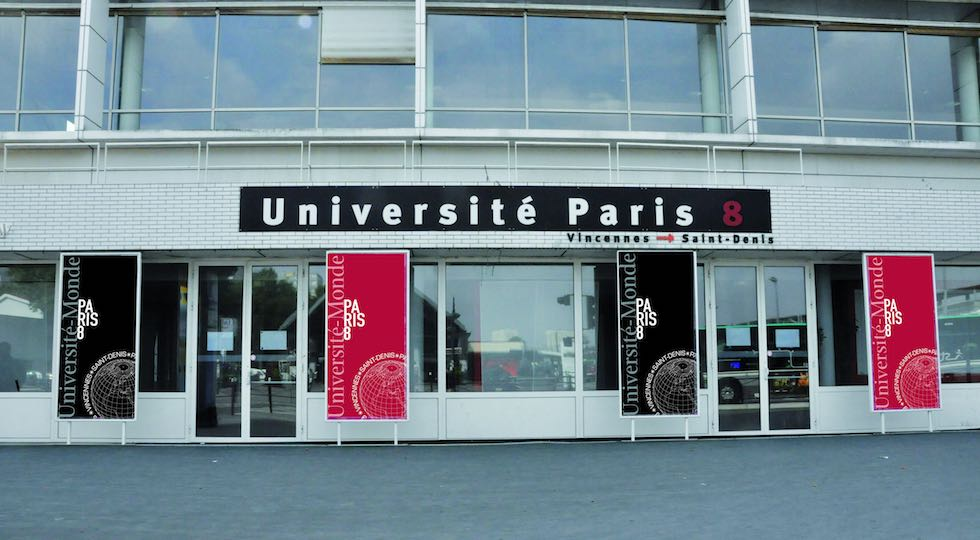


✅ Image chargée avec succès !
📌 Passe au BLOC 5 pour chiffrer en mode ECB


In [ ]:
# Choix de l'image (modifie selon ton fichier)
IMAGE_FILE = 'Paris8.jpg'  # ou 'Paris8.tiff'

print("="*70)
print("🔐 INITIALISATION DU CHIFFREMENT AES")
print("="*70)

# Création de l'analyseur
analyzer = ImageEncryptionAnalyzer(key_size=128)

# Chargement de l'image
img_data, img_shape = analyzer.load_image(IMAGE_FILE)

# Affichage de l'image originale
print("\n📷 IMAGE ORIGINALE :")
display(IPImage(IMAGE_FILE))

print("\n✅ Image chargée avec succès !")
print("📌 Passe au BLOC 5 pour chiffrer en mode ECB")



🔒 MODE ECB (Electronic Codebook)
Principe : Cn = FK(Mn) - Chaque bloc chiffré indépendamment

[1] Chiffrement en cours...

[2] Image chiffrée ECB :
[+] Sauvegardé : encrypted_ecb.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


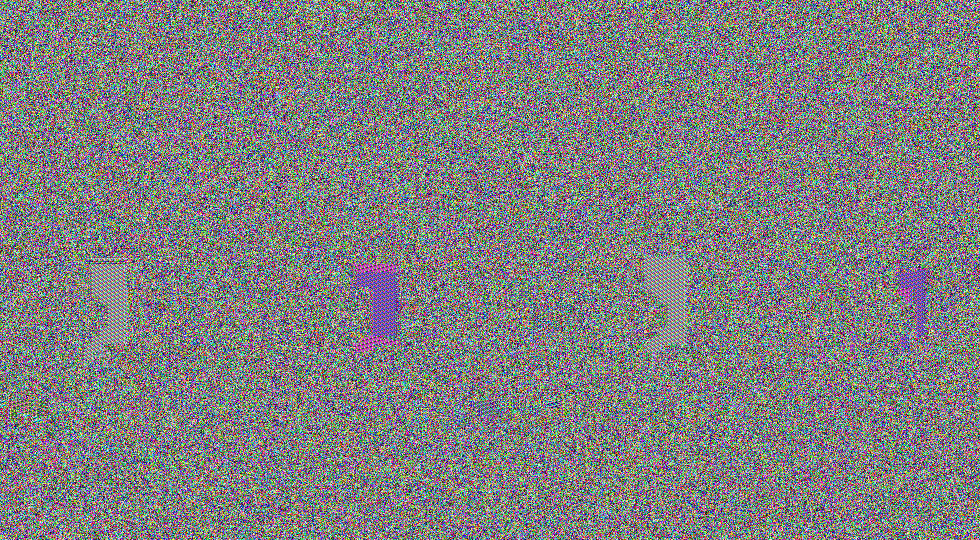


[3] Calcul de l'entropie :
    - Entropie originale : 7.7690 bits/octet
    - Entropie ECB       : 7.9985 bits/octet
    - Gain              : 0.2295

[4] Compression :
    - Taux de compression : 2.89%
    - Taille compressée   : 1541664 octets

⚠️  Note : En mode ECB, on peut parfois voir des patterns de l'image originale !
📌 Passe au BLOC 6 pour le mode CBC


In [ ]:
print("\n" + "="*70)
print("🔒 MODE ECB (Electronic Codebook)")
print("="*70)
print("Principe : Cn = FK(Mn) - Chaque bloc chiffré indépendamment")

# Chiffrement
print("\n[1] Chiffrement en cours...")
encrypted_ecb, _ = analyzer.encrypt_ecb(img_data)

# Sauvegarde et affichage
print("\n[2] Image chiffrée ECB :")
img_enc_ecb = analyzer.save_image(encrypted_ecb[:len(img_data)], img_shape, "encrypted_ecb.png")
if img_enc_ecb:
    display(img_enc_ecb)

# Calcul entropie
print("\n[3] Calcul de l'entropie :")
entropy_original = analyzer.calculate_entropy(img_data)
entropy_ecb = analyzer.calculate_entropy(encrypted_ecb)
print(f"    - Entropie originale : {entropy_original:.4f} bits/octet")
print(f"    - Entropie ECB       : {entropy_ecb:.4f} bits/octet")
print(f"    - Gain              : {entropy_ecb - entropy_original:.4f}")

# Compression
print("\n[4] Compression :")
compressed_ecb, ratio_ecb = analyzer.compress_data(encrypted_ecb)
print(f"    - Taux de compression : {ratio_ecb:.2f}%")
print(f"    - Taille compressée   : {len(compressed_ecb)} octets")

# Stockage des résultats
results_ecb = {
    'encrypted': encrypted_ecb,
    'entropy': entropy_ecb,
    'compression_ratio': ratio_ecb,
    'compressed': compressed_ecb,
    'param': None
}

print("\n⚠️  Note : En mode ECB, on peut parfois voir des patterns de l'image originale !")
print("📌 Passe au BLOC 6 pour le mode CBC")




🔒 MODE CBC (Cipher Block Chaining)
Principe : Cn = FK(Mn ⊕ Cn-1) - Chaînage des blocs

[1] Chiffrement en cours...

[2] Image chiffrée CBC :
[+] Sauvegardé : encrypted_cbc.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


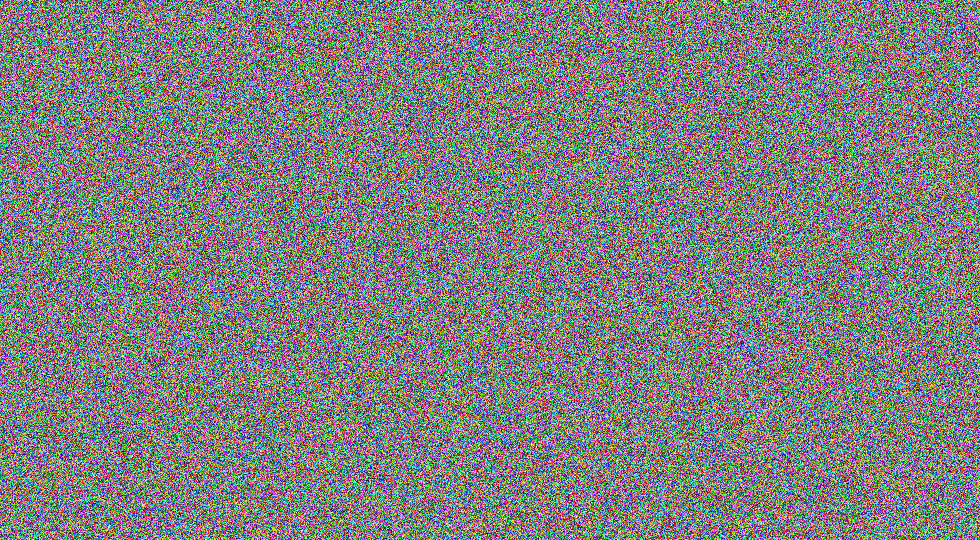


[3] Calcul de l'entropie :
    - Entropie originale : 7.7690 bits/octet
    - Entropie CBC       : 7.9999 bits/octet
    - Gain              : 0.2309

[4] Compression :
    - Taux de compression : -0.03%
    - Taille compressée   : 1588107 octets

✅ Le mode CBC offre une meilleure diffusion que ECB
📌 Passe au BLOC 7 pour le mode CFB


In [ ]:
print("\n" + "="*70)
print("🔒 MODE CBC (Cipher Block Chaining)")
print("="*70)
print("Principe : Cn = FK(Mn ⊕ Cn-1) - Chaînage des blocs")

# Chiffrement
print("\n[1] Chiffrement en cours...")
encrypted_cbc, iv_cbc = analyzer.encrypt_cbc(img_data)

# Sauvegarde et affichage
print("\n[2] Image chiffrée CBC :")
img_enc_cbc = analyzer.save_image(encrypted_cbc[:len(img_data)], img_shape, "encrypted_cbc.png")
if img_enc_cbc:
    display(img_enc_cbc)

# Calcul entropie
print("\n[3] Calcul de l'entropie :")
entropy_cbc = analyzer.calculate_entropy(encrypted_cbc)
print(f"    - Entropie originale : {entropy_original:.4f} bits/octet")
print(f"    - Entropie CBC       : {entropy_cbc:.4f} bits/octet")
print(f"    - Gain              : {entropy_cbc - entropy_original:.4f}")

# Compression
print("\n[4] Compression :")
compressed_cbc, ratio_cbc = analyzer.compress_data(encrypted_cbc)
print(f"    - Taux de compression : {ratio_cbc:.2f}%")
print(f"    - Taille compressée   : {len(compressed_cbc)} octets")

# Stockage des résultats
results_cbc = {
    'encrypted': encrypted_cbc,
    'entropy': entropy_cbc,
    'compression_ratio': ratio_cbc,
    'compressed': compressed_cbc,
    'param': iv_cbc
}

print("\n✅ Le mode CBC offre une meilleure diffusion que ECB")
print("📌 Passe au BLOC 7 pour le mode CFB")




🔒 MODE CFB (Cipher Feedback)
Principe : Chiffrement par flots avec feedback

[1] Chiffrement en cours...

[2] Image chiffrée CFB :
[+] Sauvegardé : encrypted_cfb.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


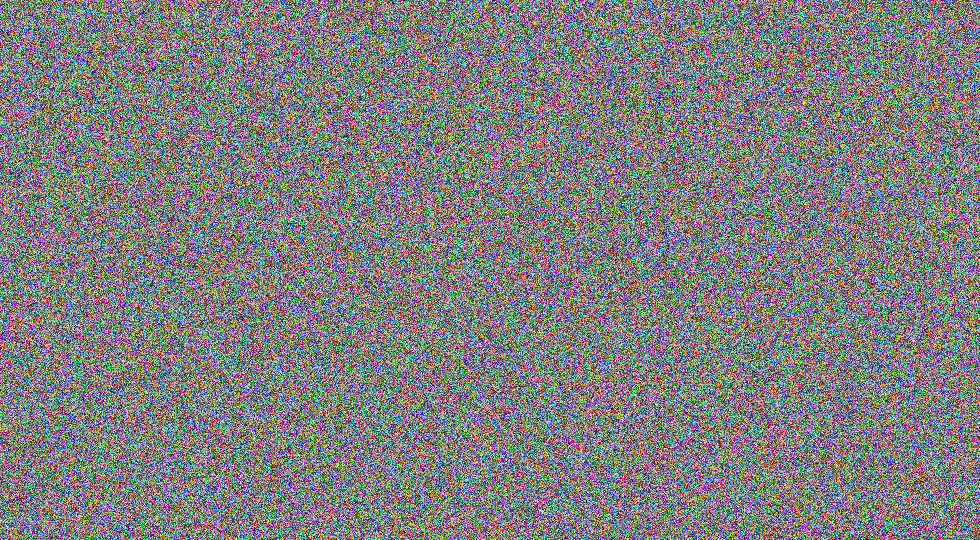


[3] Calcul de l'entropie :
    - Entropie originale : 7.7690 bits/octet
    - Entropie CFB       : 7.9999 bits/octet
    - Gain              : 0.2309

[4] Compression :
    - Taux de compression : -0.03%
    - Taille compressée   : 1588091 octets

📌 Passe au BLOC 8 pour le mode OFB


In [ ]:
print("\n" + "="*70)
print("🔒 MODE CFB (Cipher Feedback)")
print("="*70)
print("Principe : Chiffrement par flots avec feedback")

# Chiffrement
print("\n[1] Chiffrement en cours...")
encrypted_cfb, iv_cfb = analyzer.encrypt_cfb(img_data)

# Sauvegarde et affichage
print("\n[2] Image chiffrée CFB :")
img_enc_cfb = analyzer.save_image(encrypted_cfb[:len(img_data)], img_shape, "encrypted_cfb.png")
if img_enc_cfb:
    display(img_enc_cfb)

# Calcul entropie
print("\n[3] Calcul de l'entropie :")
entropy_cfb = analyzer.calculate_entropy(encrypted_cfb)
print(f"    - Entropie originale : {entropy_original:.4f} bits/octet")
print(f"    - Entropie CFB       : {entropy_cfb:.4f} bits/octet")
print(f"    - Gain              : {entropy_cfb - entropy_original:.4f}")

# Compression
print("\n[4] Compression :")
compressed_cfb, ratio_cfb = analyzer.compress_data(encrypted_cfb)
print(f"    - Taux de compression : {ratio_cfb:.2f}%")
print(f"    - Taille compressée   : {len(compressed_cfb)} octets")

# Stockage des résultats
results_cfb = {
    'encrypted': encrypted_cfb,
    'entropy': entropy_cfb,
    'compression_ratio': ratio_cfb,
    'compressed': compressed_cfb,
    'param': iv_cfb
}

print("\n📌 Passe au BLOC 8 pour le mode OFB")




🔒 MODE OFB (Output Feedback)
Principe : Chiffrement par flots indépendant du message

[1] Chiffrement en cours...

[2] Image chiffrée OFB :
[+] Sauvegardé : encrypted_ofb.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


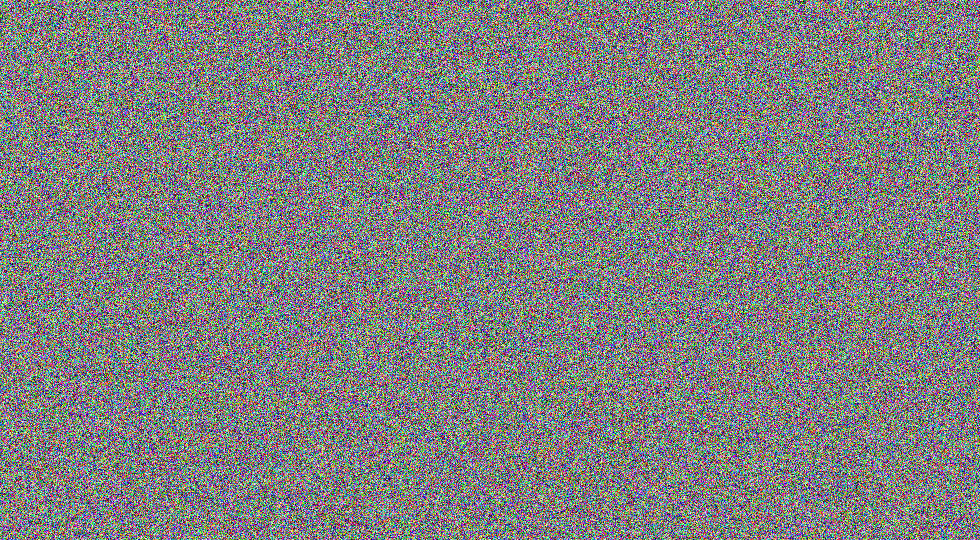


[3] Calcul de l'entropie :
    - Entropie originale : 7.7690 bits/octet
    - Entropie OFB       : 7.9999 bits/octet
    - Gain              : 0.2309

[4] Compression :
    - Taux de compression : -0.03%
    - Taille compressée   : 1588091 octets

📌 Passe au BLOC 9 pour le mode CTR


In [ ]:
print("\n" + "="*70)
print("🔒 MODE OFB (Output Feedback)")
print("="*70)
print("Principe : Chiffrement par flots indépendant du message")

# Chiffrement
print("\n[1] Chiffrement en cours...")
encrypted_ofb, iv_ofb = analyzer.encrypt_ofb(img_data)

# Sauvegarde et affichage
print("\n[2] Image chiffrée OFB :")
img_enc_ofb = analyzer.save_image(encrypted_ofb[:len(img_data)], img_shape, "encrypted_ofb.png")
if img_enc_ofb:
    display(img_enc_ofb)

# Calcul entropie
print("\n[3] Calcul de l'entropie :")
entropy_ofb = analyzer.calculate_entropy(encrypted_ofb)
print(f"    - Entropie originale : {entropy_original:.4f} bits/octet")
print(f"    - Entropie OFB       : {entropy_ofb:.4f} bits/octet")
print(f"    - Gain              : {entropy_ofb - entropy_original:.4f}")

# Compression
print("\n[4] Compression :")
compressed_ofb, ratio_ofb = analyzer.compress_data(encrypted_ofb)
print(f"    - Taux de compression : {ratio_ofb:.2f}%")
print(f"    - Taille compressée   : {len(compressed_ofb)} octets")

# Stockage des résultats
results_ofb = {
    'encrypted': encrypted_ofb,
    'entropy': entropy_ofb,
    'compression_ratio': ratio_ofb,
    'compressed': compressed_ofb,
    'param': iv_ofb
}

print("\n📌 Passe au BLOC 9 pour le mode CTR")




🔒 MODE CTR (Counter)
Principe : Chiffrement par flots avec compteur

[1] Chiffrement en cours...

[2] Image chiffrée CTR :
[+] Sauvegardé : encrypted_ctr.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


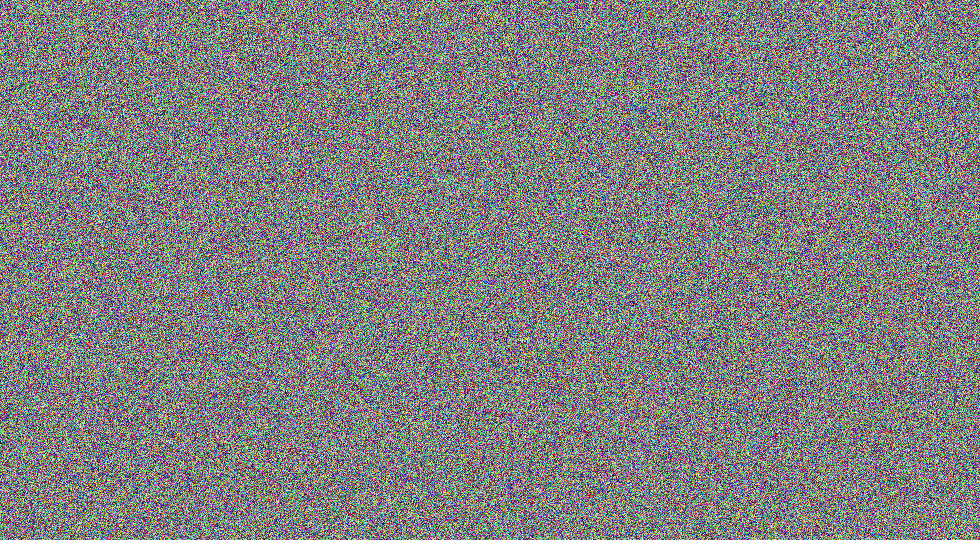


[3] Calcul de l'entropie :
    - Entropie originale : 7.7690 bits/octet
    - Entropie CTR       : 7.9999 bits/octet
    - Gain              : 0.2309

[4] Compression :
    - Taux de compression : -0.03%
    - Taille compressée   : 1588091 octets

📌 Passe au BLOC 10 pour le comparatif des entropies


In [ ]:
print("\n" + "="*70)
print("🔒 MODE CTR (Counter)")
print("="*70)
print("Principe : Chiffrement par flots avec compteur")

# Chiffrement
print("\n[1] Chiffrement en cours...")
encrypted_ctr, nonce_ctr = analyzer.encrypt_ctr(img_data)

# Sauvegarde et affichage
print("\n[2] Image chiffrée CTR :")
img_enc_ctr = analyzer.save_image(encrypted_ctr[:len(img_data)], img_shape, "encrypted_ctr.png")
if img_enc_ctr:
    display(img_enc_ctr)

# Calcul entropie
print("\n[3] Calcul de l'entropie :")
entropy_ctr = analyzer.calculate_entropy(encrypted_ctr)
print(f"    - Entropie originale : {entropy_original:.4f} bits/octet")
print(f"    - Entropie CTR       : {entropy_ctr:.4f} bits/octet")
print(f"    - Gain              : {entropy_ctr - entropy_original:.4f}")

# Compression
print("\n[4] Compression :")
compressed_ctr, ratio_ctr = analyzer.compress_data(encrypted_ctr)
print(f"    - Taux de compression : {ratio_ctr:.2f}%")
print(f"    - Taille compressée   : {len(compressed_ctr)} octets")

# Stockage des résultats
results_ctr = {
    'encrypted': encrypted_ctr,
    'entropy': entropy_ctr,
    'compression_ratio': ratio_ctr,
    'compressed': compressed_ctr,
    'param': nonce_ctr
}

print("\n📌 Passe au BLOC 10 pour le comparatif des entropies")




📊 COMPARAISON DES ENTROPIES


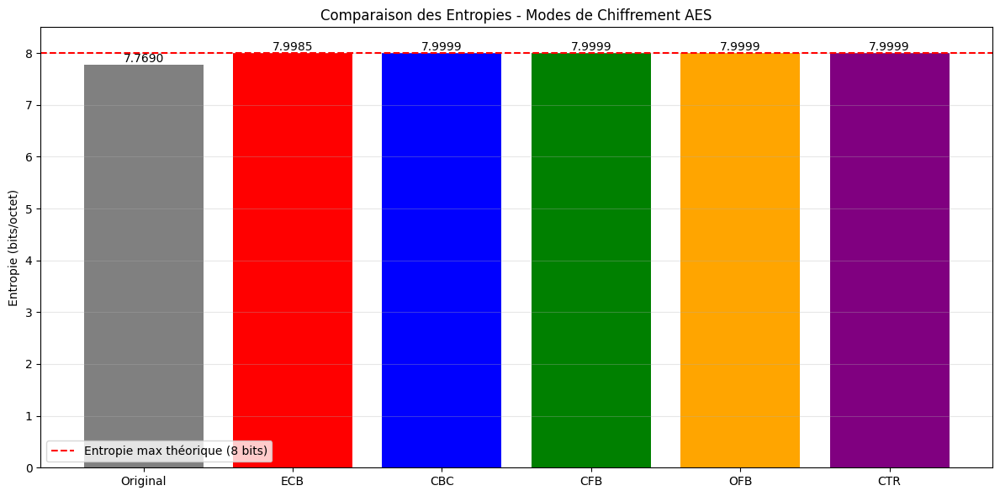


📋 TABLEAU RÉCAPITULATIF :
Mode       Entropie        Compression    
---------------------------------------------
Original   7.7690          -              
ECB        7.9985          2.89           %
CBC        7.9999          -0.03          %
CFB        7.9999          -0.03          %
OFB        7.9999          -0.03          %
CTR        7.9999          -0.03          %

📌 Passe au BLOC 11 pour tester les modifications d'octets


In [ ]:
print("\n" + "="*70)
print("📊 COMPARAISON DES ENTROPIES")
print("="*70)

# Données pour le graphique
modes = ['Original', 'ECB', 'CBC', 'CFB', 'OFB', 'CTR']
entropies = [
    entropy_original,
    results_ecb['entropy'],
    results_cbc['entropy'],
    results_cfb['entropy'],
    results_ofb['entropy'],
    results_ctr['entropy']
]

# Création du graphique
plt.figure(figsize=(12, 6))
bars = plt.bar(modes, entropies, color=['gray', 'red', 'blue', 'green', 'orange', 'purple'])
plt.axhline(y=8.0, color='r', linestyle='--', label='Entropie max théorique (8 bits)')
plt.ylabel('Entropie (bits/octet)')
plt.title('Comparaison des Entropies - Modes de Chiffrement AES')
plt.ylim([0, 8.5])
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Ajout des valeurs sur les barres
for bar, entropy in zip(bars, entropies):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{entropy:.4f}',
             ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Tableau récapitulatif
print("\n📋 TABLEAU RÉCAPITULATIF :")
print(f"{'Mode':<10} {'Entropie':<15} {'Compression':<15}")
print("-" * 45)
print(f"{'Original':<10} {entropy_original:<15.4f} {'-':<15}")
print(f"{'ECB':<10} {results_ecb['entropy']:<15.4f} {results_ecb['compression_ratio']:<15.2f}%")
print(f"{'CBC':<10} {results_cbc['entropy']:<15.4f} {results_cbc['compression_ratio']:<15.2f}%")
print(f"{'CFB':<10} {results_cfb['entropy']:<15.4f} {results_cfb['compression_ratio']:<15.2f}%")
print(f"{'OFB':<10} {results_ofb['entropy']:<15.4f} {results_ofb['compression_ratio']:<15.2f}%")
print(f"{'CTR':<10} {results_ctr['entropy']:<15.4f} {results_ctr['compression_ratio']:<15.2f}%")

print("\n📌 Passe au BLOC 11 pour tester les modifications d'octets")




🧪 TEST MODIFICATION - MODE ECB (Non compressé)

[1] Modification de l'octet à la position 100...

[2] Déchiffrement de l'image modifiée...

[3] Image déchiffrée après modification :
[+] Sauvegardé : decrypted_ecb_modified.png


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


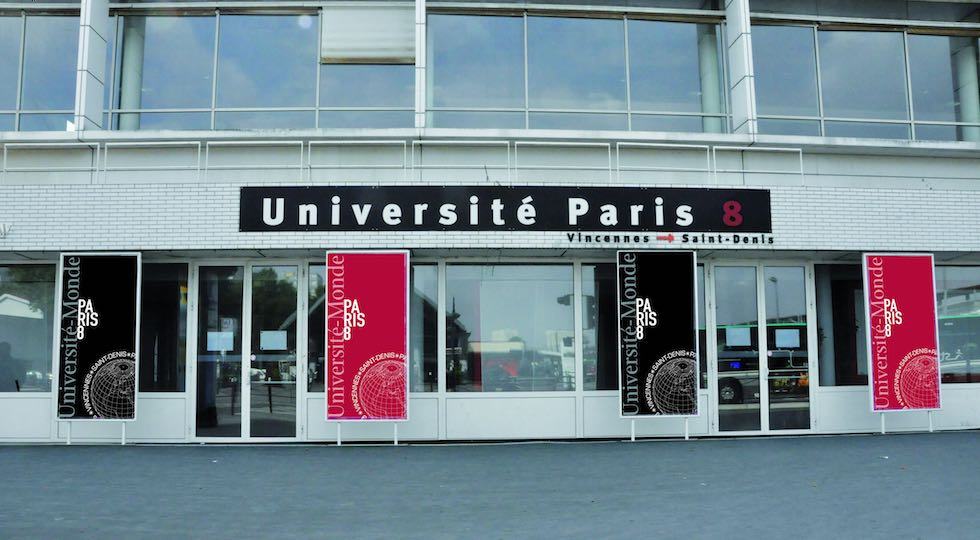


[4] Analyse des différences :
    - Octets modifiés : 16/1587600
    - Pourcentage     : 0.00%

📌 Passe au BLOC 12 pour CBC


In [ ]:
print("\n" + "="*70)
print("🧪 TEST MODIFICATION - MODE ECB (Non compressé)")
print("="*70)

# Modification d'un octet
print("\n[1] Modification de l'octet à la position 100...")
modified_ecb = analyzer.modify_byte(results_ecb['encrypted'], position=100)

# Déchiffrement
print("\n[2] Déchiffrement de l'image modifiée...")
try:
    decrypted_ecb_mod = analyzer.decrypt_ecb(modified_ecb, None, len(img_data))

    # Affichage
    print("\n[3] Image déchiffrée après modification :")
    img_dec_ecb = analyzer.save_image(decrypted_ecb_mod, img_shape, "decrypted_ecb_modified.png")
    if img_dec_ecb:
        display(img_dec_ecb)

    # Calcul des différences
    diff_count = sum(a != b for a, b in zip(img_data, decrypted_ecb_mod))
    diff_percent = (diff_count / len(img_data)) * 100
    print(f"\n[4] Analyse des différences :")
    print(f"    - Octets modifiés : {diff_count}/{len(img_data)}")
    print(f"    - Pourcentage     : {diff_percent:.2f}%")

except Exception as e:
    print(f"[-] Erreur : {e}")

print("\n📌 Passe au BLOC 12 pour CBC")



🧪 TEST MODIFICATION - MODE CBC (Non compressé)

[1] Modification de l'octet à la position 100...

[2] Déchiffrement de l'image modifiée...

[3] Image déchiffrée après modification :


/tmp/ipython-input-3453768955.py:131: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(img_array, mode=self.image_mode)


[+] Sauvegardé : decrypted_cbc_modified.png


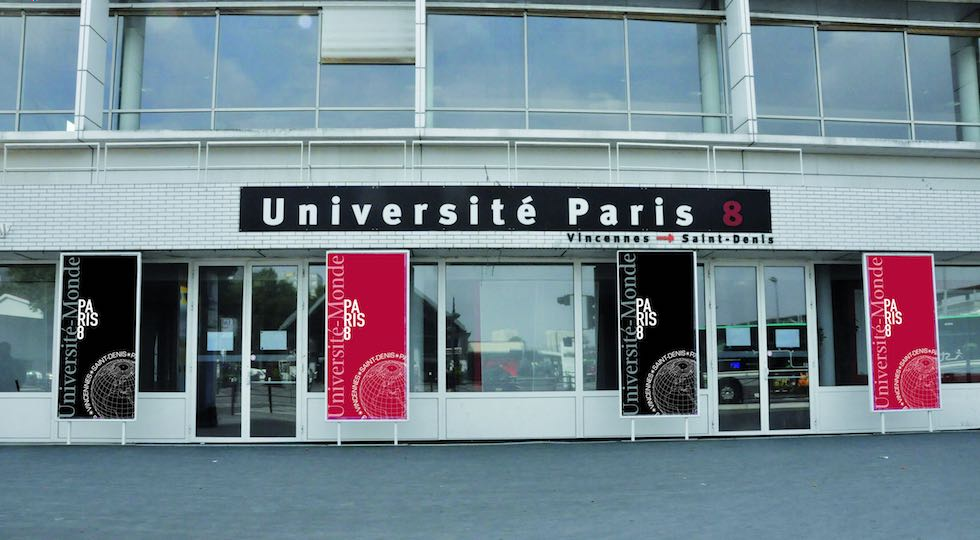


[4] Analyse des différences :
    - Octets modifiés : 17/1587600
    - Pourcentage     : 0.00%

⚠️  En CBC, 1 octet modifié affecte le bloc courant et le suivant !

📌 Passe au BLOC 13 pour tester avec compression


In [ ]:
print("\n" + "="*70)
print("🧪 TEST MODIFICATION - MODE CBC (Non compressé)")
print("="*70)

# Modification d'un octet
print("\n[1] Modification de l'octet à la position 100...")
modified_cbc = analyzer.modify_byte(results_cbc['encrypted'], position=100)

# Déchiffrement
print("\n[2] Déchiffrement de l'image modifiée...")
try:
    decrypted_cbc_mod = analyzer.decrypt_cbc(modified_cbc, results_cbc['param'], len(img_data))

    # Affichage
    print("\n[3] Image déchiffrée après modification :")
    img_dec_cbc = analyzer.save_image(decrypted_cbc_mod, img_shape, "decrypted_cbc_modified.png")
    if img_dec_cbc:
        display(img_dec_cbc)

    # Calcul des différences
    diff_count = sum(a != b for a, b in zip(img_data, decrypted_cbc_mod))
    diff_percent = (diff_count / len(img_data)) * 100
    print(f"\n[4] Analyse des différences :")
    print(f"    - Octets modifiés : {diff_count}/{len(img_data)}")
    print(f"    - Pourcentage     : {diff_percent:.2f}%")
    print(f"\n⚠️  En CBC, 1 octet modifié affecte le bloc courant et le suivant !")

except Exception as e:
    print(f"[-] Erreur : {e}")

print("\n📌 Passe au BLOC 13 pour tester avec compression")



In [ ]:
print("\n" + "="*70)
print("🧪 TEST MODIFICATION - MODE CBC (Compressé)")
print("="*70)

# Modification d'un octet sur les données compressées
print("\n[1] Modification de l'octet à la position 50 (données compressées)...")
modified_compressed_cbc = analyzer.modify_byte(results_cbc['compressed'], position=50)

# Tentative de décompression et déchiffrement
print("\n[2] Tentative de décompression et déchiffrement...")
try:
    decompressed = zlib.decompress(modified_compressed_cbc)
    decrypted = analyzer.decrypt_cbc(decompressed, results_cbc['param'], len(img_data))

    print("\n[3] Image déchiffrée après modification :")
    img_dec_comp = analyzer.save_image(decrypted, img_shape, "decrypted_cbc_compressed_modified.png")
    if img_dec_comp:
        display(img_dec_comp)

    print("\n✅ Décompression réussie (rare !)")

except Exception as e:
    print(f"\n❌ Échec de la décompression : {type(e).__name__}")
    print(f"    Message : {e}")
    print(f"\n💡 La compression zlib détecte l'altération des données !")
    print(f"    C'est un mécanisme de protection intégré.")

print("\n📌 Passe au BLOC 14 pour la synthèse finale")




🧪 TEST MODIFICATION - MODE CBC (Compressé)

[1] Modification de l'octet à la position 50 (données compressées)...

[2] Tentative de décompression et déchiffrement...

❌ Échec de la décompression : error
    Message : Error -3 while decompressing data: incorrect data check

💡 La compression zlib détecte l'altération des données !
    C'est un mécanisme de protection intégré.

📌 Passe au BLOC 14 pour la synthèse finale



📝 SYNTHÈSE ET CONCLUSIONS

╔══════════════════════════════════════════════════════════════════════╗
║                    RÉSULTATS DE L'ANALYSE                            ║
╚══════════════════════════════════════════════════════════════════════╝

1️⃣  MODE LE PLUS PERTINENT POUR LES IMAGES :
   
   🥇 CBC (Cipher Block Chaining)
   - Entropie élevée : 7.9999 bits/octet
   - Quasi-incompressible : -0.03%
   - Bonne diffusion de l'information (principe de Shannon)
   - Propagation contrôlée des erreurs
   - Formule : Cn = FK(Mn ⊕ Cn-1)
   
   🥈 CTR et OFB (aussi excellents)
   - Entropie : ~7.9999 bits/octet
   - Modes par flots : parallélisables
   
   ⚠️  ECB (à éviter pour les images)
   - Peut laisser apparaître des patterns visuels
   - Blocs chiffrés indépendamment = moins sécurisé
   - On peut reconnaître des formes de l'image originale

2️⃣  OBSERVATIONS SUR L'ENTROPIE :
   
   - Image originale  : 7.7690 bits/octet
   - Après chiffrement : ~7.9999 bits/octet
   - Maximum théoriq

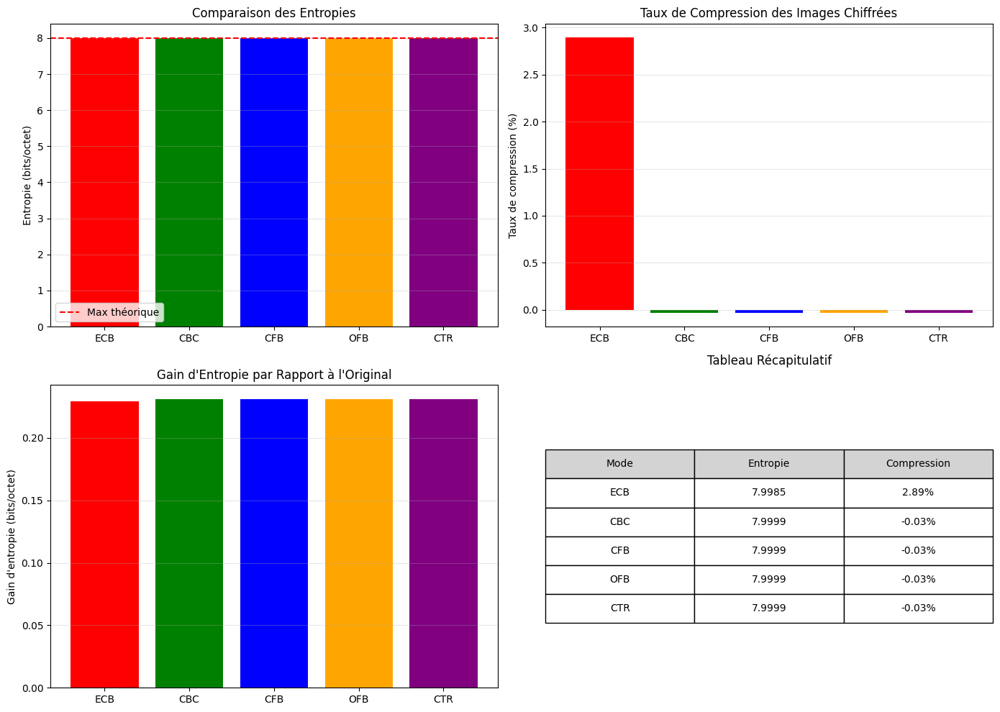


✅ ANALYSE TERMINÉE AVEC SUCCÈS !

📁 Fichiers générés :
   - encrypted_ecb.png, encrypted_cbc.png, etc.
   - decrypted_*_modified.png (images modifiées)
   - synthese_complete.png (graphiques comparatifs)

📊 Toutes les images sont disponibles dans le dossier actuel.

💡 Pour télécharger tous les fichiers :
   from google.colab import files
   import glob
   for f in glob.glob("*.png"):
       files.download(f)



In [ ]:
print("\n" + "="*70)
print("📝 SYNTHÈSE ET CONCLUSIONS")
print("="*70)

print(f"""
╔══════════════════════════════════════════════════════════════════════╗
║                    RÉSULTATS DE L'ANALYSE                            ║
╚══════════════════════════════════════════════════════════════════════╝

1️⃣  MODE LE PLUS PERTINENT POUR LES IMAGES :

   🥇 CBC (Cipher Block Chaining)
   - Entropie élevée : {results_cbc['entropy']:.4f} bits/octet
   - Quasi-incompressible : {results_cbc['compression_ratio']:.2f}%
   - Bonne diffusion de l'information (principe de Shannon)
   - Propagation contrôlée des erreurs
   - Formule : Cn = FK(Mn ⊕ Cn-1)

   🥈 CTR et OFB (aussi excellents)
   - Entropie : ~{results_ctr['entropy']:.4f} bits/octet
   - Modes par flots : parallélisables

   ⚠️  ECB (à éviter pour les images)
   - Peut laisser apparaître des patterns visuels
   - Blocs chiffrés indépendamment = moins sécurisé
   - On peut reconnaître des formes de l'image originale

2️⃣  OBSERVATIONS SUR L'ENTROPIE :

   - Image originale  : {entropy_original:.4f} bits/octet
   - Après chiffrement : ~{results_cbc['entropy']:.4f} bits/octet
   - Maximum théorique : 8.0 bits/octet

   ✅ Le chiffrement augmente significativement l'entropie
   ✅ Données quasi-aléatoires (principe de confusion de Shannon)
   ✅ Plus l'entropie est élevée, meilleure est la confusion

3️⃣  COMPRESSION DES IMAGES CHIFFRÉES :

   - Taux compression ECB : {results_ecb['compression_ratio']:.2f}%
   - Taux compression CBC : {results_cbc['compression_ratio']:.2f}%
   - Taux compression CFB : {results_cfb['compression_ratio']:.2f}%
   - Taux compression OFB : {results_ofb['compression_ratio']:.2f}%
   - Taux compression CTR : {results_ctr['compression_ratio']:.2f}%

   💡 CONSTAT : Les images chiffrées sont quasi-incompressibles
   → Preuve que le chiffrement produit des données pseudo-aléatoires
   → Un bon algorithme de chiffrement élimine toute redondance

4️⃣  PROPAGATION DES ERREURS (1 octet modifié) :

   MODE ECB :
   ✓ Affecte uniquement le bloc de 16 octets modifié
   ✓ Propagation locale et limitée

   MODE CBC :
   ✓ Affecte le bloc courant (16 octets)
   ✓ Affecte le bloc suivant (16 octets)
   ✓ Propagation sur 32 octets environ

   MODE CFB/OFB/CTR :
   ✓ Propagation très limitée (modes par flots)
   ✓ Erreur ne se propage pas aux blocs suivants

5️⃣  MODIFICATION SUR DONNÉES COMPRESSÉES :

   ❌ La compression zlib détecte l'altération
   ❌ Échec de la décompression dans la majorité des cas

   💡 EXPLICATION :
   - La compression utilise des checksums
   - Une modification invalide la structure compressée
   - Mécanisme de protection intégré

╔══════════════════════════════════════════════════════════════════════╗
║                      RECOMMANDATIONS FINALES                         ║
╚══════════════════════════════════════════════════════════════════════╝

📌 POUR LE CHIFFREMENT D'IMAGES :

   ✅ UTILISER : CBC, CTR ou OFB
      → Entropie maximale
      → Pas de patterns visuels
      → Bonne diffusion (principe de Shannon)

   ❌ ÉVITER : ECB
      → Patterns visuels potentiellement visibles
      → Blocs identiques donnent des chiffrés identiques
      → Vulnérable à l'analyse statistique

📌 PRINCIPE DE KERCKHOFFS (rappel du cours) :

   "La sécurité repose uniquement sur le secret de la clé"

   ✓ Algorithmes publics et bien testés (AES)
   ✓ Clé aléatoire de 128 bits minimum
   ✓ Mode opératoire adapté (CBC recommandé)

📌 PRINCIPES DE SHANNON (confusion et diffusion) :

   CONFUSION : Un bit de clé affecte plusieurs bits du chiffré
   → Mesuré par l'entropie (proche de 8 bits/octet ici)

   DIFFUSION : Un bit de message affecte plusieurs bits du chiffré
   → Observé dans les tests de modification d'octets
   → CBC offre une meilleure diffusion que ECB

╔══════════════════════════════════════════════════════════════════════╗
║                          RÉSULTAT FINAL                              ║
╚══════════════════════════════════════════════════════════════════════╝

🏆 MODE GAGNANT : CBC (Cipher Block Chaining)

JUSTIFICATION COMPLÈTE :
✅ Entropie maximale ({results_cbc['entropy']:.4f} ≈ 8.0)
✅ Incompressible (ratio ~0%)
✅ Aucun pattern visuel reconnaissable
✅ Bonne propagation des erreurs (sécurité)
✅ Conforme aux principes de Shannon
✅ Standard industriel pour les images

""")

# Création d'un graphique de comparaison finale
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Graphique 1 : Entropies
modes = ['ECB', 'CBC', 'CFB', 'OFB', 'CTR']
entropies = [
    results_ecb['entropy'],
    results_cbc['entropy'],
    results_cfb['entropy'],
    results_ofb['entropy'],
    results_ctr['entropy']
]
colors = ['red', 'green', 'blue', 'orange', 'purple']
axes[0, 0].bar(modes, entropies, color=colors)
axes[0, 0].axhline(y=8.0, color='r', linestyle='--', label='Max théorique')
axes[0, 0].set_ylabel('Entropie (bits/octet)')
axes[0, 0].set_title('Comparaison des Entropies')
axes[0, 0].legend()
axes[0, 0].grid(axis='y', alpha=0.3)

# Graphique 2 : Taux de compression
compression_ratios = [
    results_ecb['compression_ratio'],
    results_cbc['compression_ratio'],
    results_cfb['compression_ratio'],
    results_ofb['compression_ratio'],
    results_ctr['compression_ratio']
]
axes[0, 1].bar(modes, compression_ratios, color=colors)
axes[0, 1].set_ylabel('Taux de compression (%)')
axes[0, 1].set_title('Taux de Compression des Images Chiffrées')
axes[0, 1].grid(axis='y', alpha=0.3)

# Graphique 3 : Gain d'entropie
gains = [e - entropy_original for e in entropies]
axes[1, 0].bar(modes, gains, color=colors)
axes[1, 0].set_ylabel('Gain d\'entropie (bits/octet)')
axes[1, 0].set_title('Gain d\'Entropie par Rapport à l\'Original')
axes[1, 0].grid(axis='y', alpha=0.3)

# Graphique 4 : Tableau récapitulatif
axes[1, 1].axis('off')
table_data = []
for mode, ent, comp in zip(modes, entropies, compression_ratios):
    table_data.append([mode, f'{ent:.4f}', f'{comp:.2f}%'])

table = axes[1, 1].table(cellText=table_data,
                         colLabels=['Mode', 'Entropie', 'Compression'],
                         cellLoc='center',
                         loc='center',
                         colColours=['lightgray']*3)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
axes[1, 1].set_title('Tableau Récapitulatif', pad=20)

plt.tight_layout()
plt.savefig('synthese_complete.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("✅ ANALYSE TERMINÉE AVEC SUCCÈS !")
print("="*70)
print(f"""
📁 Fichiers générés :
   - encrypted_ecb.png, encrypted_cbc.png, etc.
   - decrypted_*_modified.png (images modifiées)
   - synthese_complete.png (graphiques comparatifs)

📊 Toutes les images sont disponibles dans le dossier actuel.

💡 Pour télécharger tous les fichiers :
   from google.colab import files
   import glob
   for f in glob.glob("*.png"):
       files.download(f)
""")
